In [78]:
#imports
from pathlib import Path
import os
import matplotlib.pyplot as plt
from PIL import Image


# Find the repository folder when running here or inside notebooks.
project_folder = Path.cwd()
if project_folder.name == "notebooks":
    project_folder = project_folder.parent


How many actual species do we have?

In [79]:
from pathlib import Path
import os
image_folder = project_folder / "CUB_200_2011" / "images"

folder_names = os.listdir(image_folder)

for name in folder_names:
    print(name)

001.Black_footed_Albatross
002.Laysan_Albatross
003.Sooty_Albatross
004.Groove_billed_Ani
005.Crested_Auklet
006.Least_Auklet
007.Parakeet_Auklet
008.Rhinoceros_Auklet
009.Brewer_Blackbird
010.Red_winged_Blackbird
011.Rusty_Blackbird
012.Yellow_headed_Blackbird
013.Bobolink
014.Indigo_Bunting
015.Lazuli_Bunting
016.Painted_Bunting
017.Cardinal
018.Spotted_Catbird
019.Gray_Catbird
020.Yellow_breasted_Chat
021.Eastern_Towhee
022.Chuck_will_Widow
023.Brandt_Cormorant
024.Red_faced_Cormorant
025.Pelagic_Cormorant
026.Bronzed_Cowbird
027.Shiny_Cowbird
028.Brown_Creeper
029.American_Crow
030.Fish_Crow
031.Black_billed_Cuckoo
032.Mangrove_Cuckoo
033.Yellow_billed_Cuckoo
034.Gray_crowned_Rosy_Finch
035.Purple_Finch
036.Northern_Flicker
037.Acadian_Flycatcher
038.Great_Crested_Flycatcher
039.Least_Flycatcher
040.Olive_sided_Flycatcher
041.Scissor_tailed_Flycatcher
042.Vermilion_Flycatcher
043.Yellow_bellied_Flycatcher
044.Frigatebird
045.Northern_Fulmar
046.Gadwall
047.American_Goldfinch
048.Eu

found 200 species with their names

How many total images of all species from all sub-folders?

In [80]:
image_files = list(image_folder.rglob("*.jpg"))
print("Total images:", len(image_files))

Total images: 11796


lets compare it with image.txt file that is inside the dataset folders

In [81]:
with open(image_folder.parent / "images.txt", encoding="utf-8") as file:
    listed_images = file.readlines()

print("Images in folders:", len(image_files))
print("Images listed in images.txt:", len(listed_images))
print("Difference:", len(image_files) - len(listed_images))

Images in folders: 11796
Images listed in images.txt: 11788
Difference: 8


Found 11,796 JPG files in the image folders, but images.txt lists 11,788 images, a difference of 8, Why is that? lets compare files names to see what is missing

In [82]:
text = "".join(listed_images)
for image in image_files:
    if image.name not in text:
        print(image.name)

Brewer_Blackbird_0028_2682_rgb.jpg
Pelagic_Cormorant_0022_23802_rgb.jpg
Ivory_Gull_0040_49180_rgb.jpg
Ivory_Gull_0085_49456_rgb.jpg
Western_Gull_0002_54825_rgb.jpg
Mallard_0130_76836_rgb.jpg
Clark_Nutcracker_0020_85099_rgb.jpg
White_Necked_Raven_0070_102645_rgb.jpg


lets compare the images visually to see if there is a difference

Original image


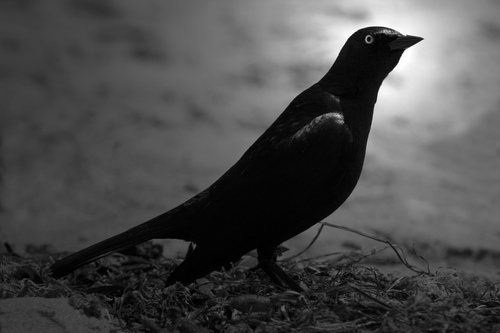

Extra image


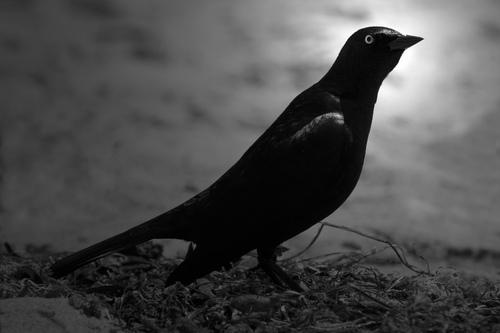

In [83]:
folder = image_folder / "009.Brewer_Blackbird"

original = Image.open(folder / "Brewer_Blackbird_0028_2682.jpg")
extra = Image.open(folder / "Brewer_Blackbird_0028_2682_rgb.jpg")

print("Original image")
display(original)

print("Extra image")
display(extra)

No visual difference, will use only images listed in images.txt to preserve the official dataset and splits.

How many images does each species have?

In [84]:
species_counts = []

for name in folder_names:
    count = text.count(name + "/")
    species_counts.append(count)
    print(name, count)


001.Black_footed_Albatross 60
002.Laysan_Albatross 60
003.Sooty_Albatross 58
004.Groove_billed_Ani 60
005.Crested_Auklet 44
006.Least_Auklet 41
007.Parakeet_Auklet 53
008.Rhinoceros_Auklet 48
009.Brewer_Blackbird 59
010.Red_winged_Blackbird 60
011.Rusty_Blackbird 60
012.Yellow_headed_Blackbird 56
013.Bobolink 60
014.Indigo_Bunting 60
015.Lazuli_Bunting 58
016.Painted_Bunting 58
017.Cardinal 57
018.Spotted_Catbird 45
019.Gray_Catbird 59
020.Yellow_breasted_Chat 59
021.Eastern_Towhee 60
022.Chuck_will_Widow 56
023.Brandt_Cormorant 59
024.Red_faced_Cormorant 52
025.Pelagic_Cormorant 60
026.Bronzed_Cowbird 60
027.Shiny_Cowbird 60
028.Brown_Creeper 59
029.American_Crow 60
030.Fish_Crow 60
031.Black_billed_Cuckoo 60
032.Mangrove_Cuckoo 53
033.Yellow_billed_Cuckoo 59
034.Gray_crowned_Rosy_Finch 59
035.Purple_Finch 60
036.Northern_Flicker 60
037.Acadian_Flycatcher 59
038.Great_Crested_Flycatcher 60
039.Least_Flycatcher 59
040.Olive_sided_Flycatcher 60
041.Scissor_tailed_Flycatcher 60
042.Vermi

In [85]:
print("Most images in one species:", max(species_counts))
print("Fewest images in one species:", min(species_counts))

Most images in one species: 60
Fewest images in one species: 41


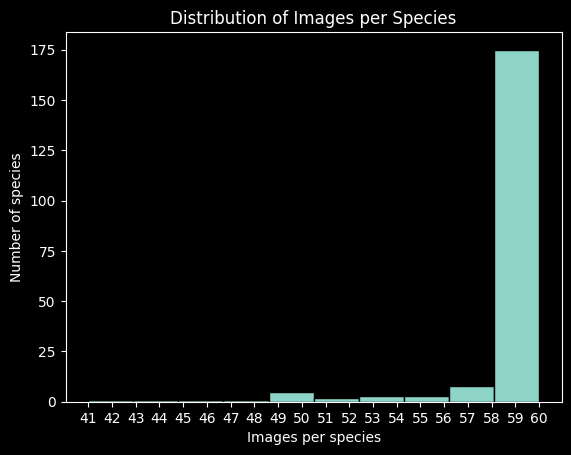

41 images: 1 species
42 images: 0 species
43 images: 0 species
44 images: 1 species
45 images: 1 species
46 images: 0 species
47 images: 0 species
48 images: 1 species
49 images: 1 species
50 images: 4 species
51 images: 1 species
52 images: 1 species
53 images: 3 species
54 images: 0 species
55 images: 0 species
56 images: 3 species
57 images: 2 species
58 images: 6 species
59 images: 31 species
60 images: 144 species


In [86]:
plt.hist(species_counts, bins=10, edgecolor="black")
plt.xlabel("Images per species")
plt.ylabel("Number of species")
plt.title("Distribution of Images per Species")
plt.xticks(range(41, 61))
plt.show()

for image_count in range(41, 61):
    number_of_species = species_counts.count(image_count)
    print(image_count, "images:", number_of_species, "species")

The dataset is fairly balanced, with 41–60 images per species and most species having 59–60.

lets look at a few sample images to inspect the birds, backgrounds, and photo quality

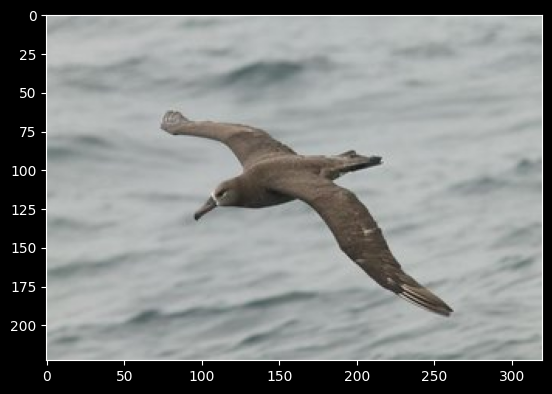

Resolution: 320 × 223


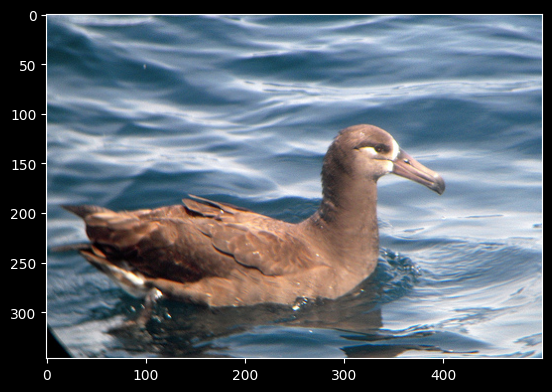

Resolution: 500 × 347


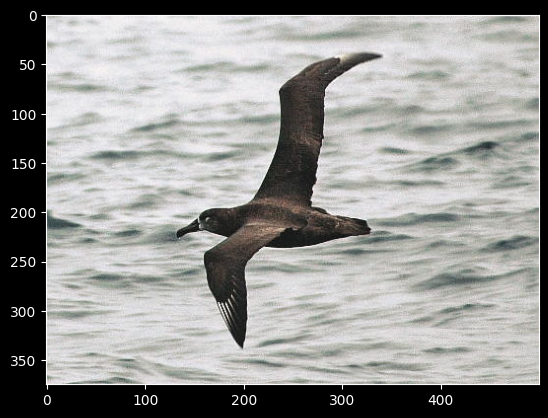

Resolution: 500 × 375


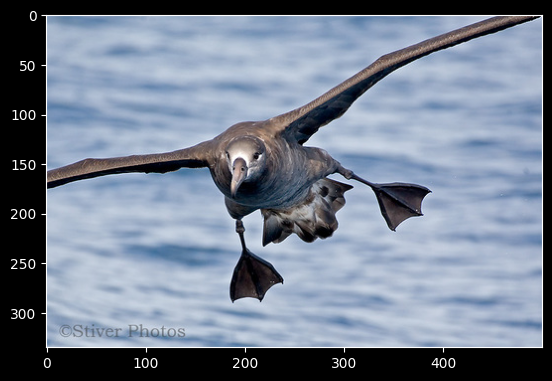

Resolution: 500 × 335


In [87]:
for filename in image_files[:4]:
    image = plt.imread(filename)
    plt.imshow(image, cmap="gray")
    plt.show()

    print("Resolution:", image.shape[1], "×", image.shape[0])

Image resolutions vary, so we will resize images to a consistent input size before training.

In [88]:
widths = []
heights = []

for filename in image_files:
    with Image.open(filename) as image:
        widths.append(image.width)
        heights.append(image.height)

print("Width range:", min(widths), "to", max(widths), "pixels")
print("Height range:", min(heights), "to", max(heights), "pixels")

Width range: 121 to 500 pixels
Height range: 120 to 500 pixels


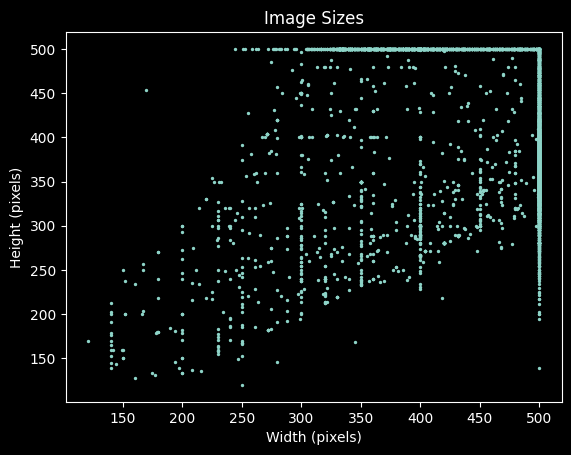

In [89]:
plt.scatter(widths, heights, s=2)
plt.xlabel("Width (pixels)")
plt.ylabel("Height (pixels)")
plt.title("Image Sizes")
plt.show()

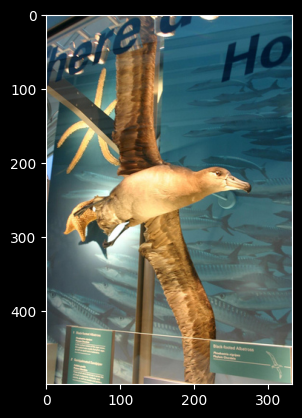

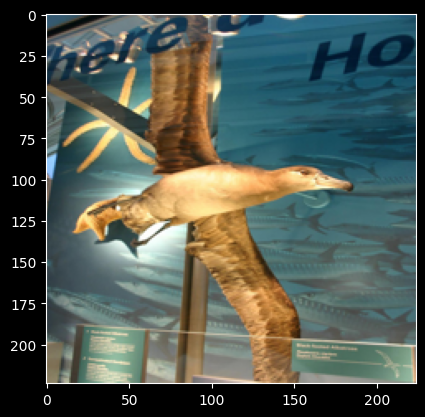

In [90]:
original = Image.open(image_files[43])
resized = original.resize((224, 224))

plt.imshow(original)
plt.show()
plt.imshow(resized)
plt.show()

image didnt get destored much and detials stay the same, resultion quality performance should be evaluated

lets check and find images that cannot be fully loaded.

In [91]:
broken_images = []
for filename in image_files:
    try:
        with Image.open(filename) as image:
            image.load()
    except OSError:
        broken_images.append(filename)

print("Unreadable images:", len(broken_images))

Unreadable images: 0


No unreadable images were found

In [92]:
official_images = []

for line in listed_images:
    filename = line.split()[1]
    official_images.append(image_folder / filename)

print("Selected images:", len(official_images))

image_modes = []

for filename in official_images:
    with Image.open(filename) as image:
        image_modes.append(image.mode)

print("Color images:", image_modes.count("RGB"))
print("Grayscale images:", image_modes.count("L"))



Selected images: 11788
Color images: 11780
Grayscale images: 8


Of the 11,788 official images, 11,780 are RGB and eight are grayscale. We will convert grayscale inputs to three channels for consistency during classification.

In [93]:
fingerprints = []

for filename in official_images:
    contents = filename.read_bytes()
    fingerprints.append(hash(contents))

print("Possible duplicates:", len(fingerprints) - len(set(fingerprints)))

Possible duplicates: 1


In [94]:
for position in range(len(fingerprints)):
    first_position = fingerprints.index(fingerprints[position])

    if first_position != position:
        first = official_images[first_position]
        second = official_images[position]

        print("First:", first.name)
        print("Second:", second.name)
        print("Identical contents:", first.read_bytes() == second.read_bytes())

First: Pigeon_Guillemot_0018_40195.jpg
Second: Pigeon_Guillemot_0081_40339.jpg
Identical contents: True


Found one exact duplicate pair: Pigeon_Guillemot_0018_40195.jpg and Pigeon_Guillemot_0081_40339.jpg. we will need to remove one

training and test images count

In [95]:
split_flags = []

with open(image_folder.parent / "train_test_split.txt") as file:
    for line in file:
        split_flags.append(line.split()[1])

print("Training images:", split_flags.count("1"))
print("Test images:", split_flags.count("0"))

Training images: 5994
Test images: 5794


Almost Half for each training and testing

*///////////////////////////////////////////////////////CAPTIONS////////////////////////////////////////////////////////*

In [96]:
caption_folder = project_folder / "cvpr2016_cub" / "text_c10"

caption_files = list(caption_folder.rglob("*.txt"))

print("Caption files:", len(caption_files))

Caption files: 11788


In [97]:
with open(caption_files[0], encoding="utf-8") as file:
    captions = file.readlines()

for caption in captions:
    print(caption.strip())

print("Number of captions:", len(captions))

the medium sized bird has a dark grey color, a black downward curved beak, and long wings.
the bird is dark grey brown with a thick curved bill and a flat shaped tail.
bird has brown body feathers, white breast feathers and black beak
this bird has a dark brown overall body color, with a small white patch around the base of the bill.
the bird has very long and large brown wings, as well as a black body and a long black beak.
it is a type of albatross with black wings, tail, back and beak, and has a white ring at the base of its beak.
this bird has brown plumage and a white ring at the base of its long, curved brown beak.
the entire body is dark brown, as is the bill, with a white band encircling where the bill meets the head.
this bird is gray in color, with a large curved beak.
a large gray bird with a long wingspan and a long black beak.
Number of captions: 10


In [98]:
caption_counts = []

for filename in caption_files:
    with open(filename, encoding="utf-8") as file:
        captions = file.readlines()

    caption_counts.append(len(captions))

print("Fewest captions:", min(caption_counts))
print("Most captions:", max(caption_counts))
print("Total captions:", sum(caption_counts))

Fewest captions: 10
Most captions: 10
Total captions: 117880


All 11,788 caption files contain exactly 10 lines each, totaling 117,880 caption entries.

Lets check for empty captions

In [99]:
empty_captions = 0
duplicate_captions = 0
for filename in caption_files:
    with open(filename, encoding="utf-8") as file:
        captions = file.read().splitlines()
        for caption in captions:
            if caption.strip() == "":
                empty_captions = empty_captions + 1

        repeats = len(captions) - len(set(captions))
        duplicate_captions = duplicate_captions + repeats

print("Empty captions:", empty_captions)
print("Repeated captions:", duplicate_captions)

Empty captions: 0
Repeated captions: 1306


No empty captions were found. There are 1,306 repeated caption entries within individual image files

Lets measure captions length

Shortest caption: 1 words
Longest caption: 65 words
Average length: 15.23 words


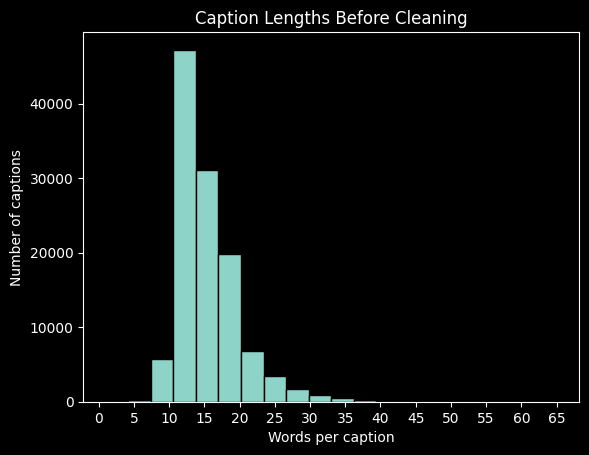

In [100]:
caption_lengths = []

for filename in caption_files:
    with open(filename, encoding="utf-8") as file:
        for caption in file:
            word_count = len(caption.split())
            caption_lengths.append(word_count)

print("Shortest caption:", min(caption_lengths), "words")
print("Longest caption:", max(caption_lengths), "words")

average = sum(caption_lengths) / len(caption_lengths)
print("Average length:", round(average, 2), "words")

plt.hist(caption_lengths, bins=20, edgecolor="black")
plt.xlabel("Words per caption")
plt.ylabel("Number of captions")
plt.title("Caption Lengths Before Cleaning")
plt.xticks(range(0, 66, 5))
plt.show()

Caption lengths range from 1 to 65 words, averaging 15.23 words. One-word captions need inspection to check whether they provide useful descriptions.

In [101]:
# Inspect one-word captions.
for filename in caption_files:
    with open(filename, encoding="utf-8") as file:
        for caption in file:
            if len(caption.split()) == 1:
                print(filename.name)
                print(caption.strip())
                print()

Sooty_Albatross_0029_796357.txt
thisï¿½ï¿½birdï¿½ï¿½hasï¿½ï¿½aï¿½ï¿½darkï¿½ï¿½greyï¿½ï¿½belly,ï¿½ï¿½darkerï¿½ï¿½greyï¿½ï¿½wings,ï¿½ï¿½aï¿½ï¿½darkï¿½ï¿½brownish-greyï¿½ï¿½headï¿½ï¿½aï¿½ï¿½squaredï¿½ï¿½offï¿½ï¿½bill.

Parakeet_Auklet_0042_795961.txt
thisï¿½ï¿½birdï¿½ï¿½hasï¿½ï¿½aï¿½ï¿½blackï¿½ï¿½bodyï¿½ï¿½andï¿½ï¿½whiteï¿½ï¿½belly,ï¿½ï¿½aï¿½ï¿½slenderï¿½ï¿½whiteï¿½ï¿½cheekï¿½ï¿½patchï¿½ï¿½originatingï¿½ï¿½fromï¿½ï¿½it'sï¿½ï¿½eyes,ï¿½ï¿½andï¿½ï¿½aï¿½ï¿½short,ï¿½ï¿½rounded,ï¿½ï¿½orangeï¿½ï¿½bill.

Parakeet_Auklet_0065_795969.txt
thisï¿½ï¿½birdï¿½ï¿½hasï¿½ï¿½aï¿½ï¿½whiteï¿½ï¿½belly,ï¿½ï¿½blackï¿½ï¿½bodyï¿½ï¿½andï¿½ï¿½wings,ï¿½ï¿½aï¿½ï¿½slenderï¿½ï¿½whiteï¿½ï¿½eyeï¿½ï¿½patch,ï¿½ï¿½andï¿½ï¿½aï¿½ï¿½short,ï¿½ï¿½stubbyï¿½ï¿½orangeï¿½ï¿½bill.

Brewer_Blackbird_0079_2343.txt
thisï¿½ï¿½shortï¿½ï¿½birdï¿½ï¿½hasï¿½ï¿½aï¿½ï¿½spotted-whiteï¿½ï¿½eyering,ï¿½ï¿½anï¿½ï¿½all-blackï¿½ï¿½bodyï¿½ï¿½andï¿½ï¿½aï¿½ï¿½largeï¿½ï¿½whiteï¿½ï¿½billï¿½ï¿½withï¿½ï¿½aï¿½ï¿½blackï¿½ï¿½tip.

Brewer_Blackbird_0115_2279.txt


Some captions contain corrupted word separators, causing incorrect word counts. Others contain only “this” and provide no useful description.

lets count how many captions have these problems

In [102]:
# Count corrupted captions and captions containing only "this".
corrupted = 0
incomplete = 0

for filename in caption_files:
    with open(filename, encoding="utf-8") as file:
        for caption in file:
            if "�" in caption:
                corrupted = corrupted + 1

            if caption.strip().lower() == "this":
                incomplete = incomplete + 1

print("Captions with corrupted characters:", corrupted)
print("Captions containing only 'this':", incomplete)

Captions with corrupted characters: 56
Captions containing only 'this': 2


Found 56 captions with corrupted characters and two incomplete captions containing only “this”; these will be handled during cleaning.

lets count the vocabulary, how many different words appear in the captions, how many different words the captioning model will need to learn.

In [103]:
# Count unique words in the raw captions.
vocabulary = set()

for filename in caption_files:
    with open(filename, encoding="utf-8") as file:
        caption_text = file.read().lower()

    words = caption_text.split()
    vocabulary.update(words)

print("Unique words before cleaning:", len(vocabulary))

Unique words before cleaning: 9473


Found 9,473 unique word forms after lowercasing, before cleaning punctuation and corrupted text

In [104]:
import difflib
from collections import Counter

# Count every word, without the punctuation around it.
word_counts = Counter()
for filename in caption_files:
    with open(filename, encoding="utf-8") as file:
        for word in file.read().lower().split():
            word_counts[word.strip(".,;:!?\"'()")] += 1

common_words = []
for word in word_counts:
    if word_counts[word] >= 50:
        common_words.append(word)

# A word used only once that looks almost like a common word is probably a typo.
typos = []
for word in word_counts:
    if word_counts[word] == 1:
        match = difflib.get_close_matches(word, common_words, n=1, cutoff=0.85)
        if match:
            typos.append(word + " -> " + match[0])

print("Likely typos:", len(typos))
for typo in typos[:30]:
    print(typo)

Likely typos: 695
agrayish -> grayish
winspan -> wingspan
loarge -> large
curven -> curve
secondaries,a -> secondaries
thrat -> throat
ligt -> light
dowwnward -> downward
bleak -> beak
hover -> over
eyrings -> eyerings
completly -> completely
fether -> feather
tuffled -> ruffled
curling -> curving
unusal -> unusual
smattered -> scattered
spckles -> speckles
vbill -> bill
bac -> back
eye-brow -> eyebrow
tarusus -> tarsus
srtiped -> striped
meedium -> medium
beading -> leading
irdescent -> iridescent
mettalic -> metallic
feathets -> feathers
featrues -> features
patchj -> patch


average 15.23 words per caption

lets try images without a matching caption file.

In [105]:
missing_captions = []

for image in official_images:
    species = image.parent.name
    caption_name = image.stem + ".txt"
    caption_path = caption_folder / species / caption_name

    if not caption_path.exists():
        missing_captions.append(image.name)

print("Images without captions:", len(missing_captions))

Images without captions: 0


////////////////////////////////////////////////////////////////////////////////////////////////////////////

check whether all 200 species appear in both splits

In [106]:
train_species = []
test_species = []

for position in range(len(official_images)):
    species = official_images[position].parent.name

    if split_flags[position] == "1":
        train_species.append(species)
    else:
        test_species.append(species)

print("Species in training:", len(set(train_species)))
print("Species in testing:", len(set(test_species)))

Species in training: 200
Species in testing: 200


dataset has only about 60 images per species. we lets try augmentation

check the number of training and test images for each species

In [107]:
for species in folder_names:
    train_count = train_species.count(species)
    test_count = test_species.count(species)

    print(species, "| Training:", train_count, "| Test:", test_count)

001.Black_footed_Albatross | Training: 30 | Test: 30
002.Laysan_Albatross | Training: 30 | Test: 30
003.Sooty_Albatross | Training: 30 | Test: 28
004.Groove_billed_Ani | Training: 30 | Test: 30
005.Crested_Auklet | Training: 30 | Test: 14
006.Least_Auklet | Training: 30 | Test: 11
007.Parakeet_Auklet | Training: 30 | Test: 23
008.Rhinoceros_Auklet | Training: 30 | Test: 18
009.Brewer_Blackbird | Training: 30 | Test: 29
010.Red_winged_Blackbird | Training: 30 | Test: 30
011.Rusty_Blackbird | Training: 30 | Test: 30
012.Yellow_headed_Blackbird | Training: 30 | Test: 26
013.Bobolink | Training: 30 | Test: 30
014.Indigo_Bunting | Training: 30 | Test: 30
015.Lazuli_Bunting | Training: 30 | Test: 28
016.Painted_Bunting | Training: 30 | Test: 28
017.Cardinal | Training: 30 | Test: 27
018.Spotted_Catbird | Training: 30 | Test: 15
019.Gray_Catbird | Training: 30 | Test: 29
020.Yellow_breasted_Chat | Training: 30 | Test: 29
021.Eastern_Towhee | Training: 30 | Test: 30
022.Chuck_will_Widow | Trai

All 200 species appear in both splits. Training counts are nearly equal at 29–30 images per species, while test counts range from 11–30.

view images from different species

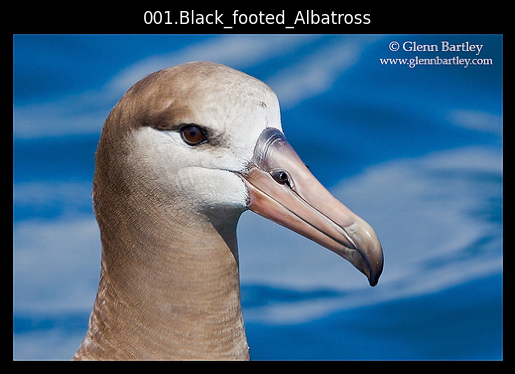

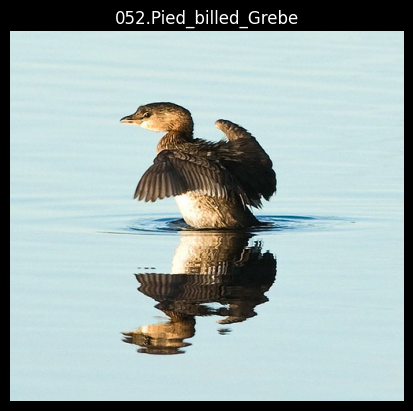

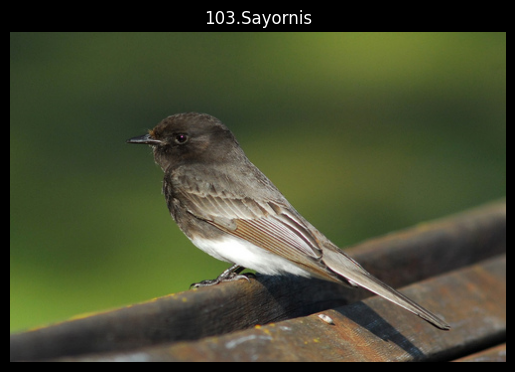

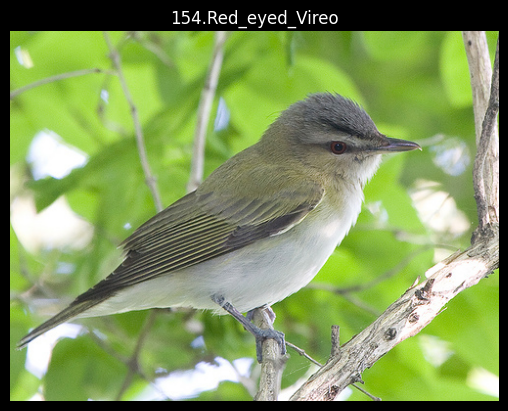

In [108]:
for position in [0, 3000, 6000, 9000]:
    filename = official_images[position]
    image = plt.imread(filename)

    plt.imshow(image, cmap="gray")
    plt.title(filename.parent.name)
    plt.axis("off")
    plt.show()

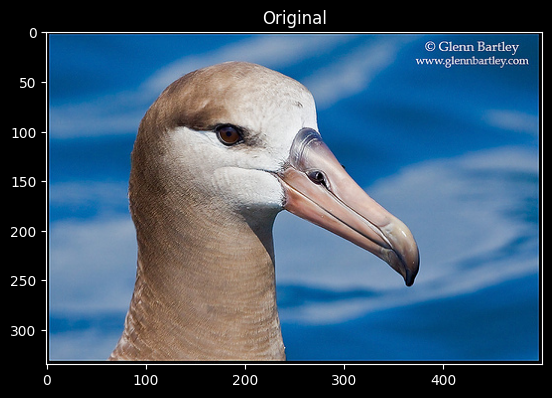

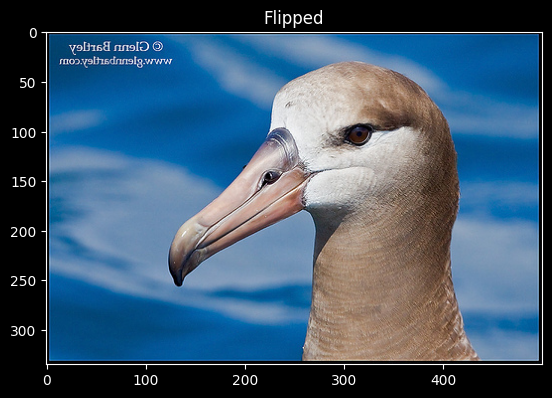

In [109]:
image = Image.open(official_images[0])
flipped = image.transpose(Image.Transpose.FLIP_LEFT_RIGHT)

plt.imshow(image)
plt.title("Original")
plt.show()

plt.imshow(flipped)
plt.title("Flipped")
plt.show()

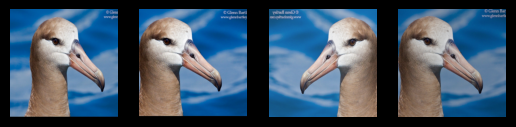

In [111]:
from torchvision import transforms

augment = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
])

for position in range(1, 5):
    plt.subplot(1, 4, position)
    plt.imshow(augment(image))
    plt.axis("off")
plt.show()

Crop, horizontal flip and lighting changes only. No vertical flip, because birds are rarely upside down. No colour changes, because colour helps tell species apart.